In [35]:
# Ma'lumotlar bilan ishlash, matematik hisob-kitoblar va vizualizatsiya uchun kutubxonalar
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Mashinali o'rganish (Scikit-Learn) modellari va yordamchi vositalari
from sklearn.linear_model import LinearRegression
import sympy as sp
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [36]:
# Fayl yo'li: VS Code da 'clean_titanic.csv' yoki 'data/clean_titanic.csv', Colabda esa '/content/clean_titanic.csv'
file_path = "clean_titanic.csv" 
df = pd.read_csv(file_path)

In [37]:
# Jadvalning qatorlar va ustunlar sonini (shape) ko'rish
df.shape

(889, 20)

In [38]:
# Chipta narxi (Fare) bo'yicha omon qolishni (Survived) bashorat qilish uchun oddiy chiziqli model
X, y = df[['Fare']], df['Survived']
lr = LinearRegression().fit(X, y)

# 0, 200 va 512 dollar to'lagan yo'lovchilar uchun bashorat qilib ko'rish
# Eslatma: Scikit-learn ogohlantirish bermasligi uchun ustun nomi ko'rsatilgan DataFrame shaklida uzatamiz
test_fares = pd.DataFrame([[0], [200], [512]], columns=['Fare'])
lr.predict(test_fares)

array([0.30227914, 0.80185135, 1.581184  ])

In [39]:
# Logistik regressiyaning asosiy faollashtirish funksiyasi (Sigmoid):
# Kiruvchi har qanday z qiymatini 0 va 1 oralig'idagi ehtimollikka aylantiradi
def sigmoid(z): return 1 / (1 + np.exp(-z))

# Turli z qiymatlari uchun sigmoid natijalarini chiqarish
print(f"z=-2 => {sigmoid(-2):.3f}")
print(f"z=0 => {sigmoid(0):.3f}")
print(f"z=0.5 => {sigmoid(0.5):.3f}")
print(f"z=2 => {sigmoid(2):.3f}")

z=-2 => 0.119
z=0 => 0.500
z=0.5 => 0.622
z=2 => 0.881


In [40]:
# Simvolik o'zgaruvchi yaratish
x = sp.symbols('x')

# Chiziqli kombinatsiya funksiyasi: kirish x, vazn (w) va siljish (bias, b)
def z(w, b, x): return w * x + b

# Turli x qiymatlarida chiziqli natijani tekshirish
print(f"w = 2.5, b=-1.4, x=0 -> {z(2.5, -1.4, 0)}")
print(f"w = 2.5, b=-1.4, x=1 -> {z(2.5, -1.4, 1)}")

w = 2.5, b=-1.4, x=0 -> -1.4
w = 2.5, b=-1.4, x=1 -> 1.1


[np.float64(-6.0), np.float64(-5.0), np.float64(-4.0), np.float64(-3.0), np.float64(-2.0), np.float64(-1.0), np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0)]


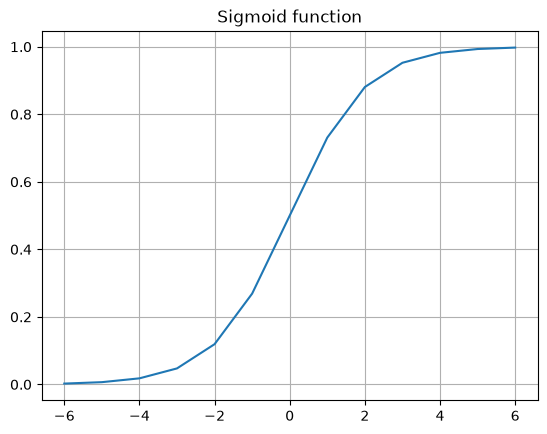

In [41]:
# -6 dan 6 gacha bo'lgan oraliqda 13 ta nuqta hosil qilish
nums = []
for step in np.linspace(-6, 6, 13):
  nums.append(step)

print(nums)

# Sigmoid funksiyasining S-simon grafigini chizish
plt.plot(nums, [sigmoid(x) for x in nums])
plt.grid(True)
plt.title("Sigmoid function")
plt.show()

In [42]:
# 'Age' ustunidagi yetishmayotgan (NaN) qiymatlarni median bilan to'ldirish
df['Age'] = df['Age'].fillna(df['Age'].median())

# 'Embarked' (chiqish porti) dagi bo'sh qiymatlarni eng ko'p uchraydigan 'S' bilan to'ldirish
if 'Embarked' in df.columns:
    df['Embarked'] = df['Embarked'].fillna('S')

# 'Sex' (jins) ustunini sonli formatga o'tkazish: male -> 0, female -> 1 (agar allaqachon kodlanmagan bo'lsa)
if df['Sex'].dtype == object:
    df['Sex'] = df['Sex'].map({"male": 0, "female": 1})

# Embarked - 3 qiymat, one-hot
# Agar 'Embarked' ustuni mavjud bo'lsa va one-hot qilinmagan bo'lsa, one-hot qilamiz
if 'Embarked' in df.columns and ('Embarked_Q' not in df.columns or 'Embarked_S' not in df.columns):
    df = pd.get_dummies(df, columns=['Embarked'], drop_first=True)

# Takroriy (dublikat) ustunlar bo'lsa, ularni tozalash
df = df.loc[:, ~df.columns.duplicated()]

In [43]:
# O'zgarishlardan so'ng jadvalning dastlabki qatorlarini tekshirish
df.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,family_size,is_alone,Title,fare_per_person,Sex_encoded,Embarked_C,Embarked_Q,Embarked_S,Age_scaled,Fare_std
0,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,2,False,Mr,3.62500,1,False,False,True,0.271174,-0.500240
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,2,False,Mrs,35.64165,0,True,False,False,0.472229,0.788947
2,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,1,True,Miss,7.92500,0,False,False,True,0.321438,-0.486650
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S,2,False,Mrs,26.55000,0,False,False,True,0.434531,0.422861
4,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S,1,True,Mr,8.05000,1,False,False,True,0.434531,-0.484133


In [44]:
# Oilaning umumiy hajmi: Aka-uka/turmush o'rtoq (SibSp) + Ota-ona/farzandlar (Parch) + yo'lovchining o'zi (+1)
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
# Yo'lovchi yolg'iz sayohat qilganmi yoki yo'qligini aniqlash (1 = yolg'iz, 0 = oilasi bilan)
df['IsAlone'] = (df['FamilySize'] == 1).astype(int)

In [45]:
# Faqat 'Fare' ustuni orqali omon qolishni bashorat qilish uchun ma'lumotlarni ajratish
X_fare = df[['Fare']]
y_fare = df['Survived']
# 80% o'qitish (train) va 20% test qismiga bo'lish
X_train_fare, X_test_fare, y_train_fare, y_test_fare = train_test_split(X_fare, y_fare, test_size=0.2, random_state=42)

In [46]:
from sklearn.preprocessing import StandardScaler
# Chipta narxini standartlashtirish (o'rtacha qiymat=0, dispersiya=1 holatiga keltirish)
sc_fare = StandardScaler().fit(X_train_fare)
X_train_s = sc_fare.transform(X_train_fare)
X_test_s = sc_fare.transform(X_test_fare)

In [47]:
# Yo'lovchilarni yosh guruhlari bo'yicha taqsimotini hisoblash
print(f"0 < age <= 15 -> {len(df[(df.Age > 0) & (df.Age <= 15)])}")
print(f"15 < age <= 30 -> {len(df[(df.Age > 15) & (df.Age <= 30)])}")
print(f"30 < age <= 45 -> {len(df[(df.Age > 30) & (df.Age <= 45)])}")
print(f"45 < age -> {len(df[df.Age > 45])}")

0 < age <= 15 -> 83
15 < age <= 30 -> 503
30 < age <= 45 -> 201
45 < age -> 102


In [48]:
# 1. 'Sex' ustunini qat'iy ravishda sonlarga o'tkazamiz (male -> 0, female -> 1)
from sklearn.linear_model import LogisticRegression


df['Sex'] = df['Sex'].map({'male': 0, 'female': 1}).fillna(df['Sex']).astype(int)

# 2. Embarked_Q va Embarked_S ustunlarini 0 va 1 ga aylantiramiz
for col in ['Embarked_Q', 'Embarked_S']:
    if col in df.columns:
        df[col] = df[col].astype(int)

# Modelga beriladigan belgilar ro'yxati
feats_all = ["Pclass", "Sex", "Age", "Fare", "FamilySize", "IsAlone", "Embarked_Q", "Embarked_S"]
y = df["Survived"]

# Ma'lumotlarni stratifikatsiya (sinflar mutanosibligini saqlagan holda) bilan train/test ga ajratish
Xtr_all, Xte_all, ytr_all, yte_all = train_test_split(df[feats_all], y, test_size=0.2, random_state=42, stratify=y)

# Belgilarni StandardScaler bilan masshtablash
sc_all = StandardScaler().fit(Xtr_all)

# Logistik regressiya modelini yaratish va o'qitish
m_all = LogisticRegression(max_iter=1000)
m_all.fit(sc_all.transform(Xtr_all), ytr_all)

# Test to'plamidagi aniqlik (Accuracy) natijasini chiqarish
print(f"Accuracy (barcha belgilar bilan): {m_all.score(sc_all.transform(Xte_all), yte_all):.4f}")

Accuracy (barcha belgilar bilan): 0.8202


In [49]:
# Test ma'lumotlarini standartlashtirish
Xte_s = sc_all.transform(Xte_all)

# Dastlabki 5 ta yo'lovchi uchun sinf bashorati (0 = vafot etgan, 1 = omon qolgan)
print("Predictions:")
display(m_all.predict(Xte_s)[:5])

# Dastlabki 2 ta yo'lovchi uchun har bir sinfga tegishlilik ehtimolligi [P(0), P(1)]
print("Probabilities:")
display(m_all.predict_proba(Xte_s)[:2])

Predictions:


array([0, 0, 0, 0, 0])

Probabilities:


array([[0.92572258, 0.07427742],
       [0.83943497, 0.16056503]])

In [50]:
# Eng asosiy 3 ta belgi: Chipta toifasi (Pclass), Jinsi (Sex) va Yoshi (Age)
feats = ["Pclass", "Sex", "Age"]

y = df["Survived"]
# Ma'lumotlarni ajratish
Xtr, Xte, ytr, yte = train_test_split(df[feats], y, test_size=0.2, random_state=42, stratify=y)

# Tanlangan 3 ta belgi bo'yicha masshtablash va modelni qayta o'qitish
sc = StandardScaler().fit(Xtr)
m = LogisticRegression(max_iter=1000)
m.fit(sc.transform(Xtr), ytr)
# 3 ta belgi bilan olingan model aniqligi
print(f"Accuracy: {m.score(sc.transform(Xte), yte)}")

Accuracy: 0.7921348314606742


In [51]:
feats = ['Pclass', 'Sex', 'Age']

# Yangi yo'lovchi ma'lumotlari: 3-toifa, Erkak (0), 20 yosh
person = {
 "Pclass": 3,
 'Sex': 0,
 "Age": 20
}

# Lug'atni DataFrame shakliga keltirish
person_df = pd.DataFrame([person])[feats]

# Model o'rgangan masshtab bo'yicha standartlashtirish
person_scaled = sc.transform(person_df)

# Sinfni (0 yoki 1) bashorat qilish
prediction = m.predict(person_scaled)[0]

# Omon qolish ehtimolliklarini olish
probabilities = m.predict_proba(person_scaled)[0]

# Natijani foydalanuvchiga tushunarli matn holida chiqarish
status = "Tirik qolgan (Survived)" if prediction == 1 else "Vafot etgan (Not Survived)"
print(f"Bashorat: {status}")
print(f"Tirik qolish ehtimoli: {probabilities[1] * 100:.2f}%")

Bashorat: Vafot etgan (Not Survived)
Tirik qolish ehtimoli: 11.66%


In [52]:
from sklearn.metrics import confusion_matrix, classification_report

# Model 3 ta ustunga moslangan, shuning uchun test ma'lumotlarini qayta masshtablaymiz
Xte_scaled = sc.transform(Xte)
pred = m.predict(Xte_scaled)

# Xatolar matritsasi va tasniflash hisoboti
print(confusion_matrix(yte, pred))
print(classification_report(yte, pred))
# FP qimmat --> Precision'ga e'tibor bering.
# FN qimmat --> Recall'ga e'tibor bering.
# Precision = TP / (TP + FP)
# Recall = TP / (TP + FN)

[[94 16]
 [21 47]]
              precision    recall  f1-score   support

           0       0.82      0.85      0.84       110
           1       0.75      0.69      0.72        68

    accuracy                           0.79       178
   macro avg       0.78      0.77      0.78       178
weighted avg       0.79      0.79      0.79       178



In [53]:
# "Hamma o'ladi" baseline (barcha bashoratlar 0)
baseline_pred = np.zeros_like(yte)

print("Baseline Confusion Matrix:")
print(confusion_matrix(yte, baseline_pred))
print("\nBaseline Classification Report:")
print(classification_report(yte, baseline_pred, zero_division=0))

# Logistic Regression modeli: Tirik qolganlar (1 class) uchun Recall 0.69 (yoki ~69%).
# Ya'ni haqiqatda tirik qolganlarning 69% ini modelimiz to'g'ri topa olgan.
# "Hamma o'ladi" baseline modeli: Tirik qolganlar (1 class) uchun Recall 0.00 (0%).
# Chunki bu model hech kimni tirik qoldi deb topa olmaydi (barcha True Positive-lar 0 ga teng).

Baseline Confusion Matrix:
[[110   0]
 [ 68   0]]

Baseline Classification Report:
              precision    recall  f1-score   support

           0       0.62      1.00      0.76       110
           1       0.00      0.00      0.00        68

    accuracy                           0.62       178
   macro avg       0.31      0.50      0.38       178
weighted avg       0.38      0.62      0.47       178



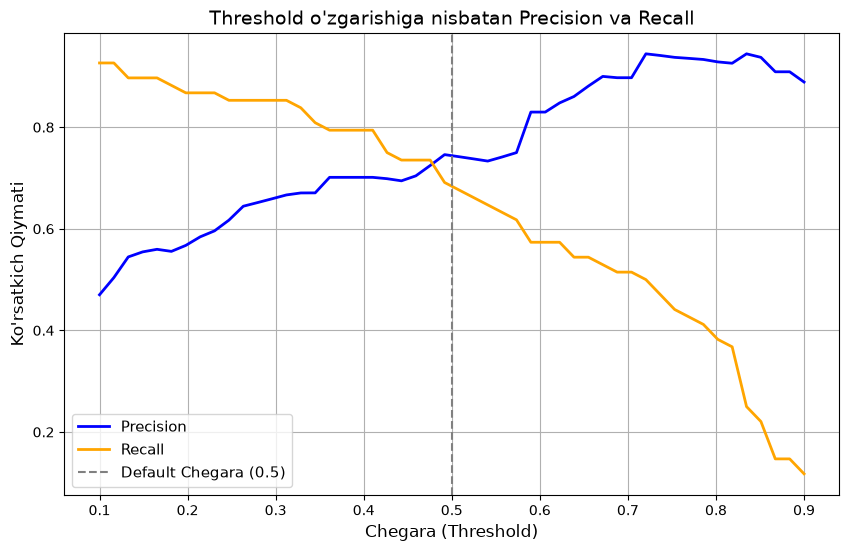

In [54]:
from sklearn.metrics import precision_score, recall_score

# Ehtimolliklarni olish (tirik qolish sinfi uchun: index 1)
probs = m.predict_proba(Xte_scaled)[:, 1]

# 0.1 dan 0.9 gacha 50 ta chegara nuqtalarini sinab ko'rish
thresholds = np.linspace(0.1, 0.9, 50)
precisions = []
recalls = []

# Har bir chegara (threshold) bo'yicha Precision va Recall ni hisoblash
for t in thresholds:
    preds_t = (probs >= t).astype(int)
    precisions.append(precision_score(yte, preds_t, zero_division=0))
    recalls.append(recall_score(yte, preds_t, zero_division=0))

# Precision va Recall o'zaro bog'liqlik egri chizig'ini vizualizatsiya qilish
plt.figure(figsize=(10, 6))
plt.plot(thresholds, precisions, label='Precision', color='blue', linewidth=2)
plt.plot(thresholds, recalls, label='Recall', color='orange', linewidth=2)
plt.title('Threshold o\'zgarishiga nisbatan Precision va Recall', fontsize=14)
plt.xlabel('Chegara (Threshold)', fontsize=12)
plt.ylabel('Ko\'rsatkich Qiymati', fontsize=12)
plt.axvline(x=0.5, color='gray', linestyle='--', label='Default Chegara (0.5)')
plt.grid(True)
plt.legend(fontsize=11)
plt.show()